--- 1. Loading TinyStories Dataset ---


README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-5852b56a2bd28f(…): reconstructing file:   0%|          |  0.00B /  248MB            

data/train-00001-of-00004-5852b56a2bd28f(…): downloading bytes:           |  0.00B            

... (5 outputs left out)

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

Loaded 300 stories.
Sample Story 1 (first 200 chars):
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on...

Avg story length: 811.9 characters

--- 6 & 7. Training Main Model (2 Layers, 4 Heads) ---


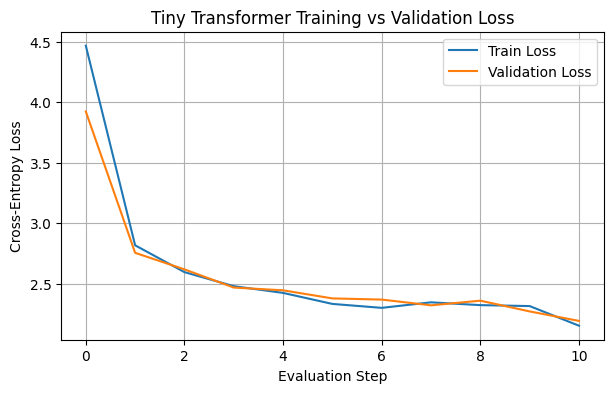


--- 8. Model Evaluation ---
Final Validation Loss: 2.1923
Perplexity: 8.96

--- 9. Generated Story ---
Once upon a time wan, ise wa wboufrokevy theap son wask t thno d fim thed aingo he rh tllp ondrery wangethopethe cinthpy. Sais hauf He. 

--- 10. Experimenting with Smaller Config (1 Layer, 2 Heads) ---
Smaller Model Val Loss: 2.2390 | Perplexity: 9.38

--- 11. Model Saved Successfully as 'tiny_transformer.pt' ---


In [1]:
!pip install -q datasets

import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from datasets import load_dataset

# Device configuration
device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(42)

# 1. Load and explore the dataset
print("--- 1. Loading TinyStories Dataset ---")
dataset = load_dataset("roneneldan/TinyStories", split="train[:300]")
stories = [item['text'] for item in dataset]
print(f"Loaded {len(stories)} stories.")
print(f"Sample Story 1 (first 200 chars):\n{stories[0][:200]}...\n")
lengths = [len(s) for s in stories]
print(f"Avg story length: {sum(lengths)/len(lengths):.1f} characters\n")

# 2. Preprocess the text (Character-level tokenization)
text = "\n".join(stories)
chars = sorted(list(set(text)))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s if c in stoi]
decode = lambda l: ''.join([itos[i] for i in l])

data = torch.tensor(encode(text), dtype=torch.long)

# 3. Prepare training and validation data
n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]

block_size = 64
batch_size = 32

def get_batch(split):
    d = train_data if split == 'train' else val_data
    ix = torch.randint(len(d) - block_size, (batch_size,))
    x = torch.stack([d[i:i+block_size] for i in ix])
    y = torch.stack([d[i+1:i+block_size+1] for i in ix])
    return x.to(device), y.to(device)

# 4. Build the Transformer architecture
class TransformerBlock(nn.Module):
    def __init__(self, embed_dim, num_heads):
        super().__init__()
        self.attn = nn.MultiheadAttention(embed_dim, num_heads, batch_first=True)
        self.ln1 = nn.LayerNorm(embed_dim)
        self.ffwd = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim)
        )
        self.ln2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        T = x.size(1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        attn_out, _ = self.attn(x, x, x, attn_mask=mask)
        x = self.ln1(x + attn_out)       # Residual connection + LayerNorm
        x = self.ln2(x + self.ffwd(x))   # Feed-forward + Residual + LayerNorm
        return x

class TinyTransformer(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, num_heads=4, num_layers=2, block_size=64):
        super().__init__()
        self.block_size = block_size
        self.token_emb = nn.Embedding(vocab_size, embed_dim)
        self.pos_emb = nn.Embedding(block_size, embed_dim)
        self.blocks = nn.Sequential(*[TransformerBlock(embed_dim, num_heads) for _ in range(num_layers)])
        self.ln_f = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok = self.token_emb(idx)
        pos = self.pos_emb(torch.arange(T, device=idx.device))
        x = self.blocks(tok + pos)
        x = self.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens=100):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]
            logits, _ = self(idx_cond)
            probs = F.softmax(logits[:, -1, :], dim=-1)
            next_tok = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, next_tok), dim=1)
        return idx

# 5 & 6. Initialize and Train the model
def train_model(num_layers=2, num_heads=4, epochs=150):
    model = TinyTransformer(vocab_size, embed_dim=64, num_heads=num_heads, num_layers=num_layers, block_size=block_size).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3)
    train_losses, val_losses = [], []

    for step in range(epochs):
        xb, yb = get_batch('train')
        _, loss = model(xb, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if step % 15 == 0 or step == epochs - 1:
            model.eval()
            with torch.no_grad():
                xv, yv = get_batch('val')
                _, vloss = model(xv, yv)
            train_losses.append(loss.item())
            val_losses.append(vloss.item())
            model.train()
    return model, train_losses, val_losses

print("--- 6 & 7. Training Main Model (2 Layers, 4 Heads) ---")
model, train_losses, val_losses = train_model(num_layers=2, num_heads=4, epochs=150)

# 7. Plot Training and Validation Loss Curves
plt.figure(figsize=(7, 4))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Evaluation Step')
plt.ylabel('Cross-Entropy Loss')
plt.title('Tiny Transformer Training vs Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

# 8. Evaluate Model (Validation Loss & Perplexity)
final_val_loss = val_losses[-1]
perplexity = math.exp(final_val_loss)
print(f"\n--- 8. Model Evaluation ---")
print(f"Final Validation Loss: {final_val_loss:.4f}")
print(f"Perplexity: {perplexity:.2f}")

# 9. Generate Stories
prompt = "Once upon a time"
context = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
generated = decode(model.generate(context, max_new_tokens=120)[0].tolist())
print(f"\n--- 9. Generated Story ---")
print(generated)

# 10. Experiment with Model Settings (1 Layer, 2 Heads vs 2 Layers, 4 Heads)
print(f"\n--- 10. Experimenting with Smaller Config (1 Layer, 2 Heads) ---")
small_model, _, small_val_losses = train_model(num_layers=1, num_heads=2, epochs=150)
print(f"Smaller Model Val Loss: {small_val_losses[-1]:.4f} | Perplexity: {math.exp(small_val_losses[-1]):.2f}")

# 11. Save the Trained Model
torch.save({
    'model_state_dict': model.state_dict(),
    'config': {'vocab_size': vocab_size, 'embed_dim': 64, 'num_heads': 4, 'num_layers': 2, 'block_size': block_size}
}, 'tiny_transformer.pt')
print("\n--- 11. Model Saved Successfully as 'tiny_transformer.pt' ---")